# Învățare Nesupervizată

In [33]:
! pip install numpy pandas scikit-learn scipy matplotlib


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: pip install --upgrade pip


In [34]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, silhouette_score
from sklearn.preprocessing import StandardScaler

DATA_PATH = Path("iris.csv")
RANDOM_STATE = 53

SURFACE, INK, INK_SECONDARY, MUTED, GRID, AXIS = (
  "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
)
SERIES = ["#2a78d6", "#eb6834", "#1baf7a"]


def style_axes(ax):
  ax.set_facecolor(SURFACE)
  ax.grid(color=GRID, linewidth=0.8)
  ax.set_axisbelow(True)
  ax.tick_params(colors=MUTED, labelcolor=INK_SECONDARY)
  for side in ("top", "right"):
    ax.spines[side].set_visible(False)
  for side in ("left", "bottom"):
    ax.spines[side].set_color(AXIS)

## 1. Analiza și vizualizarea datelor

**Verificați setul de date.**

Încărcăm datele și verificăm dimensiunea, tipurile coloanelor, valorile lipsă și rândurile duplicate, apoi afișăm statisticile descriptive ale caracteristicilor.

In [35]:
df = pd.read_csv(DATA_PATH, index_col=0)
FEATURES = ["sepal_length", "sepal_width", "petal_length", "petal_width"]
SPECIES = sorted(df["species"].unique())

print(df.shape)
df.info()
print(f"\nmissing values: {df.isna().sum().sum()}")
print(f"duplicate rows: {df.duplicated().sum()}")
df.head()

(150, 5)
<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  150 non-null    float64
 1   sepal_width   150 non-null    float64
 2   petal_length  150 non-null    float64
 3   petal_width   150 non-null    float64
 4   species       150 non-null    str    
dtypes: float64(4), str(1)
memory usage: 6.0 KB

missing values: 0
duplicate rows: 3


,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,Iris-setosa
1,4.9,3.0,1.4,0.2,Iris-setosa
2,4.7,3.2,1.3,0.2,Iris-setosa
3,4.6,3.1,1.5,0.2,Iris-setosa
4,5.0,3.6,1.4,0.2,Iris-setosa


In [36]:
df[FEATURES].describe()

,sepal_length,sepal_width,petal_length,petal_width
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.054000,3.758667,1.198667
std,0.828066,0.433594,1.764420,0.763161
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


**Verificați distribuția clusterelor.**

Clusterele reale sunt cele 3 specii. Numărăm câte exemple are fiecare specie și le afișăm într-un grafic cu bare.

species
Iris-setosa        50
Iris-versicolor    50
Iris-virginica     50
Name: count, dtype: int64


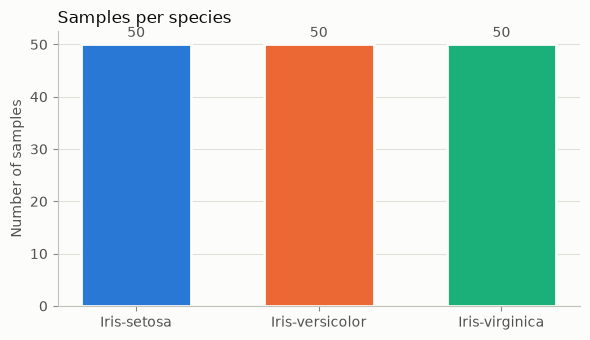

In [37]:
counts = df["species"].value_counts().reindex(SPECIES)
print(counts)

fig, ax = plt.subplots(figsize=(6, 3.5), facecolor=SURFACE)
style_axes(ax)
ax.grid(axis="x", visible=False)
bars = ax.bar(counts.index, counts.values, color=SERIES, width=0.6, edgecolor=SURFACE, linewidth=2)
ax.bar_label(bars, color=INK_SECONDARY, padding=3)
ax.set_ylabel("Number of samples", color=INK_SECONDARY)
ax.set_title("Samples per species", color=INK, loc="left")
fig.tight_layout()
plt.show()

**Verificați prin histograme dacă sunt diferențe la nivel de acceași caracteristică pentru label-uri diferite.**

Pentru fiecare caracteristică suprapunem histogramele celor 3 specii și afișăm media pe specie. Petalele separă bine speciile, iar lățimea sepalei aproape deloc.

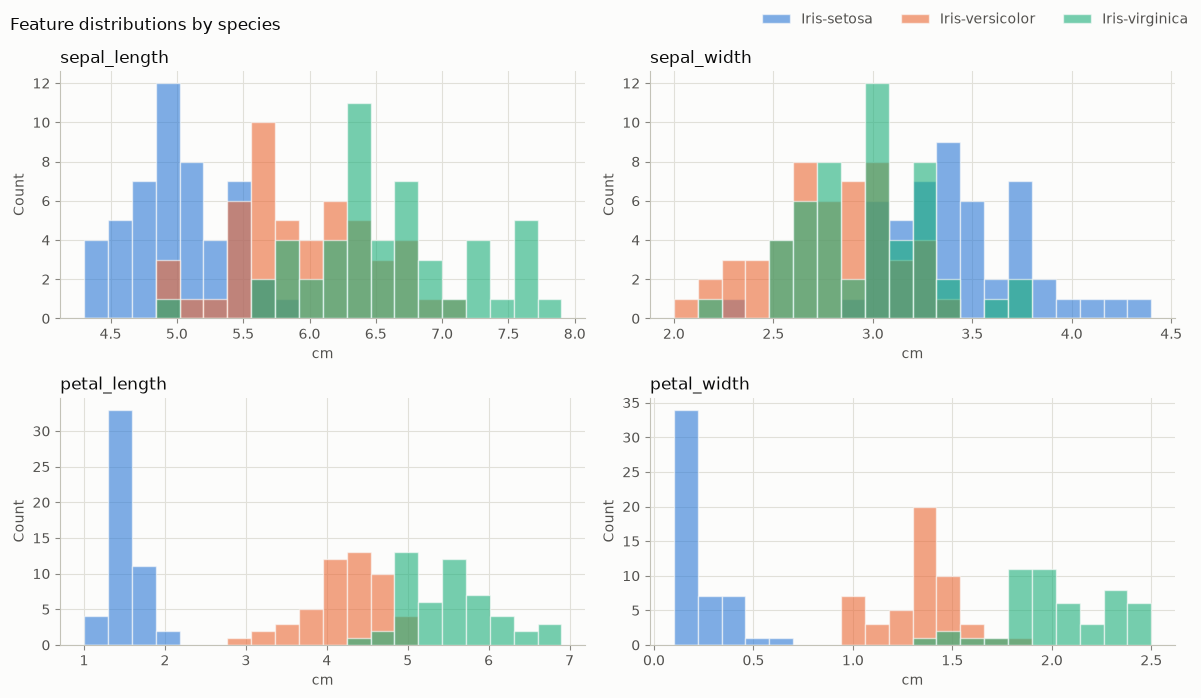

,sepal_length,sepal_width,petal_length,petal_width
species,,,,
Iris-setosa,5.01,3.42,1.46,0.24
Iris-versicolor,5.94,2.77,4.26,1.33
Iris-virginica,6.59,2.97,5.55,2.03


In [38]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7), facecolor=SURFACE)
for ax, feature in zip(axes.flat, FEATURES):
  style_axes(ax)
  bins = np.histogram_bin_edges(df[feature], bins=20)
  for species, color in zip(SPECIES, SERIES):
    ax.hist(df.loc[df["species"] == species, feature], bins=bins, color=color,
            alpha=0.6, edgecolor=SURFACE, linewidth=1, label=species)
  ax.set_title(feature, color=INK, loc="left")
  ax.set_xlabel("cm", color=INK_SECONDARY)
  ax.set_ylabel("Count", color=INK_SECONDARY)

handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper right", ncol=3, frameon=False, labelcolor=INK_SECONDARY)
fig.suptitle("Feature distributions by species", color=INK, x=0.01, ha="left")
fig.tight_layout()
plt.show()

df.groupby("species")[FEATURES].mean().round(2)

**Matricea de corelație**

Calculăm corelația Pearson între caracteristici (de la −1 la 1) și o afișăm ca heatmap.

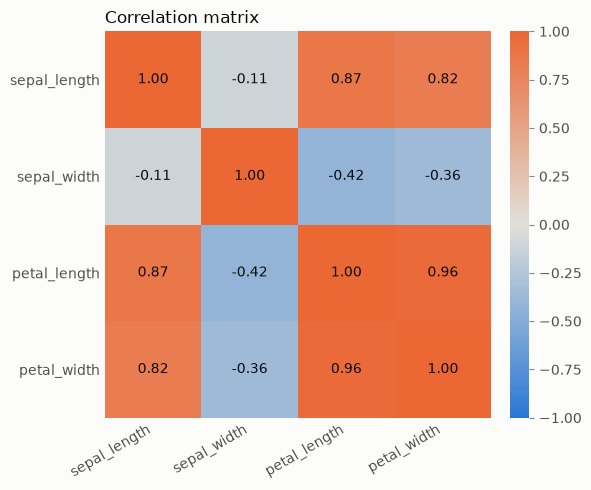

In [39]:
from matplotlib.colors import LinearSegmentedColormap

corr = df[FEATURES].corr()
cmap = LinearSegmentedColormap.from_list("diverging", [SERIES[0], "#e1e0d9", SERIES[1]])

fig, ax = plt.subplots(figsize=(6, 5), facecolor=SURFACE)
im = ax.imshow(corr, cmap=cmap, vmin=-1, vmax=1)
ax.set_xticks(range(len(FEATURES)), FEATURES, rotation=30, ha="right")
ax.set_yticks(range(len(FEATURES)), FEATURES)
ax.tick_params(colors=MUTED, labelcolor=INK_SECONDARY, length=0)
for side in ax.spines.values():
  side.set_visible(False)
for i in range(len(FEATURES)):
  for j in range(len(FEATURES)):
    ax.text(j, i, f"{corr.iat[i, j]:.2f}", ha="center", va="center", color=INK)
cbar = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
cbar.outline.set_visible(False)
cbar.ax.tick_params(colors=MUTED, labelcolor=INK_SECONDARY)
ax.set_title("Correlation matrix", color=INK, loc="left")
fig.tight_layout()
plt.show()

## 2. K-Means - Determinarea Numărului Optim de Clustere

**Vizualizați clustering-ul ierarhic printr-o dendogramă.**

Eliminăm eticheta și standardizăm caracteristicile (medie 0, deviație 1), ca toate să conteze la fel în distanța euclidiană. Construim dendrograma cu legătura Ward, iar linia punctată arată tăierea în 3 clustere.

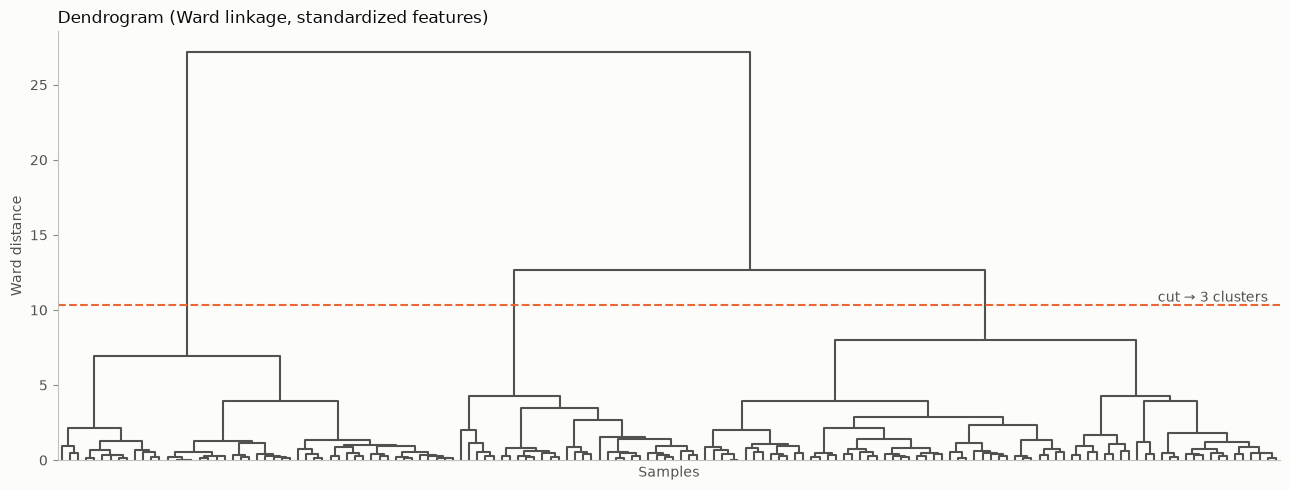

Heights of the last 5 merges: [ 4.25  6.92  8.01 12.65 27.2 ]


In [40]:
scaler = StandardScaler().fit(df[FEATURES])
X = scaler.transform(df[FEATURES])
y_true = df["species"]

Z = linkage(X, method="ward")

fig, ax = plt.subplots(figsize=(13, 5), facecolor=SURFACE)
style_axes(ax)
ax.grid(False)
dendrogram(Z, ax=ax, no_labels=True, color_threshold=0, above_threshold_color=INK_SECONDARY)

cut = (Z[-3, 2] + Z[-2, 2]) / 2
ax.axhline(cut, color=SERIES[1], linestyle="--", linewidth=1.5)
ax.annotate("cut → 3 clusters", xy=(0.99, cut), xycoords=("axes fraction", "data"),
            ha="right", va="bottom", color=INK_SECONDARY)
ax.set_ylabel("Ward distance", color=INK_SECONDARY)
ax.set_xlabel("Samples", color=INK_SECONDARY)
ax.set_title("Dendrogram (Ward linkage, standardized features)", color=INK, loc="left")
fig.tight_layout()
plt.show()

print("Heights of the last 5 merges:", np.round(Z[-5:, 2], 2))

**Alegeți un număr optim de clustere k.**

Pe lângă dendrogramă, folosim metoda cotului (WCSS în funcție de k) și coeficientul Silhouette pentru k = 1…8. Dendrograma și cotul indică k = 3, așa că alegem k = 3.

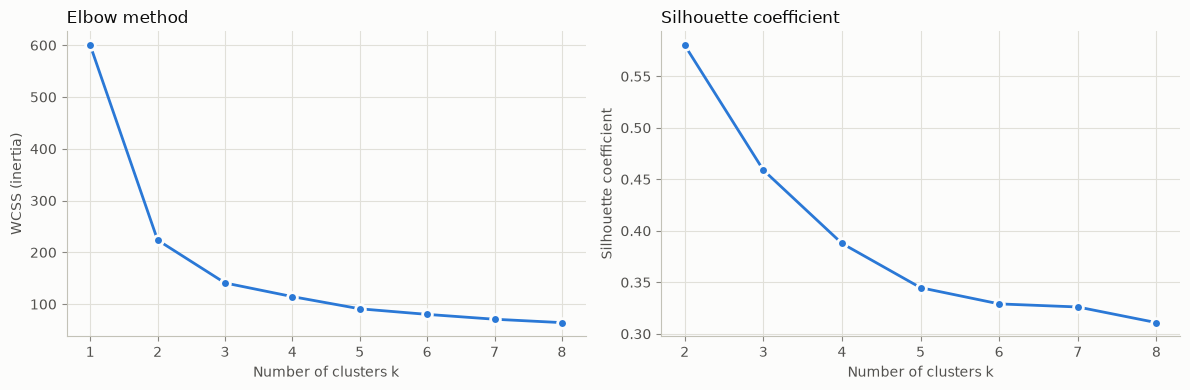

,WCSS,silhouette
k,,
1,600.000,NaN
2,223.732,0.580
3,140.966,0.459
4,114.564,0.388
5,91.029,0.345
6,80.250,0.329
7,70.885,0.326
8,64.319,0.311


In [41]:
ks = range(1, 9)
wcss, silhouettes = [], {}
for k in ks:
  km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X)
  wcss.append(km.inertia_)
  if k >= 2:
    silhouettes[k] = silhouette_score(X, km.labels_)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4), facecolor=SURFACE)
for ax in (ax1, ax2):
  style_axes(ax)
  ax.set_xlabel("Number of clusters k", color=INK_SECONDARY)

ax1.plot(list(ks), wcss, color=SERIES[0], linewidth=2, marker="o", markersize=7,
         markeredgecolor=SURFACE, markeredgewidth=2)
ax1.set_ylabel("WCSS (inertia)", color=INK_SECONDARY)
ax1.set_title("Elbow method", color=INK, loc="left")

ax2.plot(list(silhouettes), list(silhouettes.values()), color=SERIES[0], linewidth=2, marker="o",
         markersize=7, markeredgecolor=SURFACE, markeredgewidth=2)
ax2.set_ylabel("Silhouette coefficient", color=INK_SECONDARY)
ax2.set_title("Silhouette coefficient", color=INK, loc="left")
fig.tight_layout()
plt.show()

K = 3
pd.DataFrame({"WCSS": wcss, "silhouette": [np.nan, *silhouettes.values()]}, index=pd.Index(ks, name="k")).round(3)

**Antrenați un model K-Means pentru un k ales.**

Antrenăm K-Means cu k = 3 pe datele standardizate. Numerele clusterelor sunt arbitrare, așa că fiecare cluster primește numele speciei majoritare din el (doar pentru comparare, nu pentru antrenare).

In [42]:
kmeans = KMeans(n_clusters=K, n_init=10, random_state=RANDOM_STATE)
clusters = kmeans.fit_predict(X)

print(f"inertia (WCSS): {kmeans.inertia_:.2f}")
print(f"silhouette:     {silhouette_score(X, clusters):.3f}")
print("samples per cluster:", np.bincount(clusters))

crosstab = pd.crosstab(pd.Series(clusters, index=df.index, name="cluster"), y_true)
cluster_names = crosstab.idxmax(axis=1).to_dict()
cluster_species = pd.Series(clusters, index=df.index).map(cluster_names)

print(crosstab, end="\n\n")
print(f"accuracy after mapping clusters to species: {(cluster_species == y_true).mean():.3f}")
print(f"adjusted Rand index: {adjusted_rand_score(y_true, clusters):.3f}")

inertia (WCSS): 140.97
silhouette:     0.459
samples per cluster: [53 50 47]
species  Iris-setosa  Iris-versicolor  Iris-virginica
cluster                                              
0                  0               39              14
1                 50                0               0
2                  0               11              36

accuracy after mapping clusters to species: 0.833
adjusted Rand index: 0.620


**Vizualizați clusterele obținute pe un scatter plot (folosiți 2 caracteristici la alegere) pentru acel k ales.**

**Afișați centroizii pe același grafic**

Folosim lungimea și lățimea petalei. Centroizii sunt readuși în centimetri și marcați cu X pe același grafic.

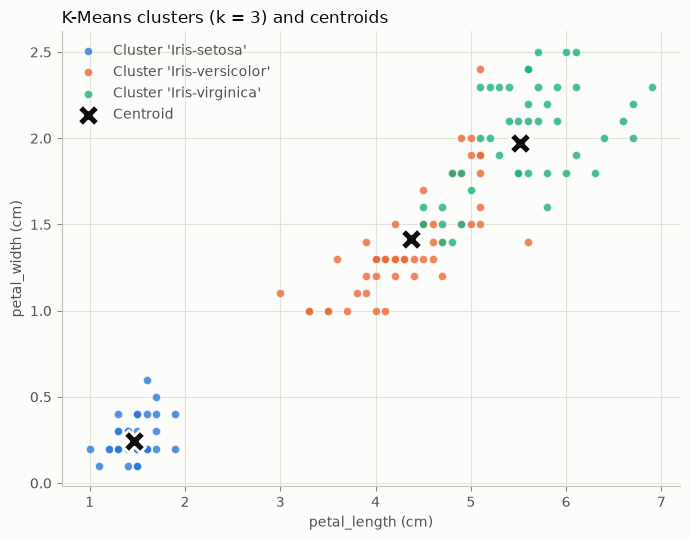

,sepal_length,sepal_width,petal_length,petal_width
centroid of cluster,,,,
Iris-versicolor,5.80,2.67,4.37,1.41
Iris-setosa,5.01,3.42,1.46,0.24
Iris-virginica,6.78,3.10,5.51,1.97


In [43]:
X_AXIS, Y_AXIS = "petal_length", "petal_width"
centroids = pd.DataFrame(scaler.inverse_transform(kmeans.cluster_centers_), columns=FEATURES)


def scatter_by(ax, groups, label):
  style_axes(ax)
  for species, color in zip(SPECIES, SERIES):
    mask = groups == species
    ax.scatter(df.loc[mask, X_AXIS], df.loc[mask, Y_AXIS], s=40, color=color,
               alpha=0.8, edgecolor=SURFACE, linewidth=1, label=label(species))
  ax.set_xlabel(f"{X_AXIS} (cm)", color=INK_SECONDARY)
  ax.set_ylabel(f"{Y_AXIS} (cm)", color=INK_SECONDARY)


fig, ax = plt.subplots(figsize=(7, 5.5), facecolor=SURFACE)
scatter_by(ax, cluster_species, lambda s: f"Cluster '{s}'")
ax.scatter(centroids[X_AXIS], centroids[Y_AXIS], s=260, marker="X", color=INK,
           edgecolor=SURFACE, linewidth=2, label="Centroid", zorder=3)
ax.set_title(f"K-Means clusters (k = {K}) and centroids", color=INK, loc="left")
ax.legend(frameon=False, labelcolor=INK_SECONDARY, loc="upper left")
fig.tight_layout()
plt.show()

centroids.round(2).set_axis([cluster_names[i] for i in range(K)]).rename_axis("centroid of cluster")

**Creați un scatter plot cu adevăratele clustere.**

Același grafic, colorat după specia reală, pentru comparație cu clusterele K-Means.

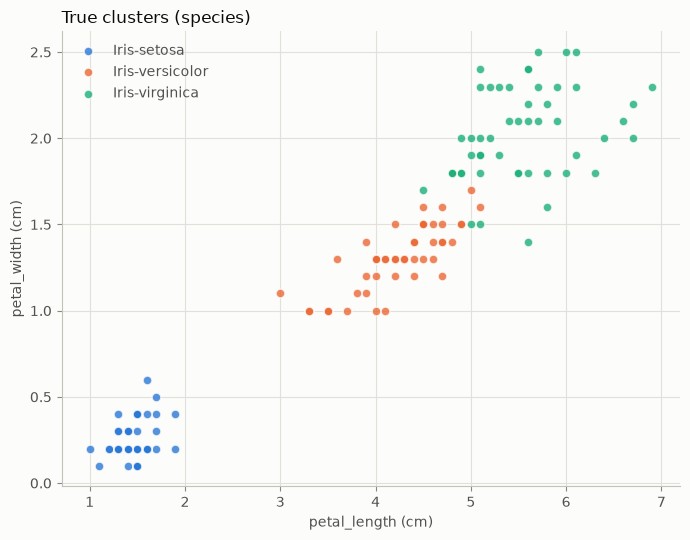

In [44]:
fig, ax = plt.subplots(figsize=(7, 5.5), facecolor=SURFACE)
scatter_by(ax, y_true, lambda s: s)
ax.set_title("True clusters (species)", color=INK, loc="left")
ax.legend(frameon=False, labelcolor=INK_SECONDARY, loc="upper left")
fig.tight_layout()
plt.show()